<a href="https://colab.research.google.com/github/fercho9586/analisys_ConnectaTel/blob/main/Project_ConnectaTel_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [20]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [21]:
# cargar archivos
# URL base apuntando directamente a tu repositorio público de GitHub
base_url = 'https://raw.githubusercontent.com/fercho9586/analisys_ConnectaTel/main/datasets/'

plans = pd.read_csv(base_url + 'plans.csv')
users = pd.read_csv(base_url + 'users_latam.csv')
usage = pd.read_csv(base_url + 'usage.csv')

In [22]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [23]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [24]:
# mostrar las primeras 5 filas de usage

usage.head(5)



,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [25]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users",users.shape )
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [26]:
# inspección de plans con .info()
plans.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 260.0+ bytes


In [27]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [28]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [29]:
# cantidad de nulos para users
print (pd.DataFrame({
    'n_nulos' : users.isna().sum(),}).sort_values(by='n_nulos',ascending=False))
print(pd.DataFrame({
 'nulos_pct' : users.isna().mean()*100,}).sort_values(by='nulos_pct',ascending=False))

            n_nulos
churn_date     3534
city            469
user_id           0
first_name        0
age               0
last_name         0
reg_date          0
plan              0
            nulos_pct
churn_date     88.350
city           11.725
user_id         0.000
first_name      0.000
age             0.000
last_name       0.000
reg_date        0.000
plan            0.000


In [30]:
# cantidad de nulos para usage
print (pd.DataFrame({
    'n_nulos' : usage.isna().sum(),}).sort_values(by='n_nulos',ascending=False))
print(pd.DataFrame({
 'nulos_pct' : usage.isna().mean()*100,}).sort_values(by='nulos_pct',ascending=False))

          n_nulos
duration    22076
length      17896
date           50
id              0
user_id         0
type            0
          nulos_pct
duration     55.190
length       44.740
date          0.125
id            0.000
user_id       0.000
type          0.000


✍️ **Diagnóstico general de valores ausentes:**
En una primera inspección cuantitativa parecía viable aplicar reglas estándar por porcentaje (eliminar columnas mayores al 50% de nulos o imputar con medidas de tendencia central). Sin embargo, al cruzar los porcentajes con la lógica de negocio y el tipo de dato, se identificó que la mayoría de los nulos aportan contexto estructural:

1. **churn_date (88.35% nulos):** Se descarta su eliminación o imputación ciega; se descubrió que el valor nulo actúa como una señal explícita de que el cliente continúa activo, por lo que se recomienda conservarlo o transformarlo en una columna indicadora (churn_flag).

2. **city (11.72% nulos):** Presenta un volumen moderado de nulos reales; se recomienda investigar su distribución y rellenar con una categoría explícita (como "Desconocido") para conservar los registros en futuros cruces demográficos.

3. **duration (55.19%) y length (44.74%):** Se identificó que son nulos estructurales condicionados por la variable categórica del tipo de evento (llamada vs. mensaje); no aplica imputar ni eliminar filas, sino mantenerlos y segmentar por tipo de registro al calcular métricas.

4. **date (menor al 1% nulos):** Al tratarse de una variable de fecha, se descarta el uso de media o mediana y se recomienda eliminar directamente esos pocos registros, logrando una limpieza segura sin pérdida relevante de información ni sesgo estadístico.**:
En una primera insp cuantitativa parecía viable aplicar reglas estándar por porcentaje (eliminar columnas mayores al 50% de nulos o imputar con medidas de tendencia central). Sin embargo, al cruzar los porcentajes con la lógica de negocio y el tipo de dato, se identificó que la mayoría de los nulos aportan contexto estructural:


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [31]:


# Explorar columnas numéricas de data users
print('Columnas numéricas de users:', users.select_dtypes(include=['number']).columns.tolist())

# 1. Definir la función
def resumen_numerico():
    columnas_numericas = users.select_dtypes(include='number')

    # 2. Iterar sobre cada columna y calcular estadísticas
    for col in columnas_numericas:
        print("Columna:", col)
        print('Minimo:', columnas_numericas[col].min())
        print('Mediana:', columnas_numericas[col].median()) # median() calcula la Mediana
        print('Promedio:', columnas_numericas[col].mean())  # mean() calcula el Promedio (o Media)
        print('Maximo:', columnas_numericas[col].max())
        print('Desviacion estandar:', columnas_numericas[col].std())
        print('-' * 50)

# 3. Llamar a la función para ver el resultado
resumen_numerico()


Columnas numéricas de users: ['user_id', 'age']
Columna: user_id
Minimo: 10000
Mediana: 11999.5
Promedio: 11999.5
Maximo: 13999
Desviacion estandar: 1154.8448669265786
--------------------------------------------------
Columna: age
Minimo: -999
Mediana: 47.0
Promedio: 33.73975
Maximo: 79
Desviacion estandar: 123.23225660193143
--------------------------------------------------


**Exploración de columnas numericas (users):**

- **user_id (Numérica - Identificador):** Al revisar el rango (mínimo y máximo), se observa una secuencia continua y uniforme sin identificadores anómalos ni códigos centinela (como 0 o valores negativos). Al ser un identificador único, sus medidas de tendencia central no se interpretan estadísticamente.

- **age (Numérica):** Se detectaron edades negativas en el resumen estadístico. Dado que una edad negativa es biológicamente imposible, se concluye que no son outliers reales, sino valores centinela utilizados para registrar datos faltantes. Se recomienda reemplazarlos por NaN antes de realizar cualquier cálculo para no sesgar la media ni la mediana de edad.

In [32]:
# explorar columnas numéricas de usage
print('Columnas numéricas de usage:', usage.select_dtypes(include=['number']).columns.tolist())

# 1. Definir la función
def resumen_numerico():
    columnas_numericas = usage.select_dtypes(include='number')

    # 2. Iterar sobre cada columna y calcular estadísticas
    for col in columnas_numericas:
        print("Columna:", col)
        print('Minimo:', columnas_numericas[col].min())
        print('Mediana:', columnas_numericas[col].median()) # median() calcula la Mediana
        print('Promedio:', columnas_numericas[col].mean())  # mean() calcula el Promedio (o Media)
        print('Maximo:', columnas_numericas[col].max())
        print('Desviacion estandar:', columnas_numericas[col].std())
        print('-' * 50)

# 3. Llamar a la función para ver el resultado
resumen_numerico()

Columnas numéricas de usage: ['id', 'user_id', 'duration', 'length']
Columna: id
Minimo: 1
Mediana: 20000.5
Promedio: 20000.5
Maximo: 40000
Desviacion estandar: 11547.149720457714
--------------------------------------------------
Columna: user_id
Minimo: 10000
Mediana: 12013.0
Promedio: 12002.405975
Maximo: 13999
Desviacion estandar: 1157.2795642190558
--------------------------------------------------
Columna: duration
Minimo: 0.0
Mediana: 3.5
Promedio: 5.202237223833965
Maximo: 120.0
Desviacion estandar: 6.8427012805619025
--------------------------------------------------
Columna: length
Minimo: 0.0
Mediana: 50.0
Promedio: 52.12739775606225
Maximo: 1490.0
Desviacion estandar: 56.61118270878634
--------------------------------------------------


**Exploración de columnas numéricas (usage):**

- **id y user_id (Identificadores):** Al tratarse de llaves identificadoras, no se evalúan sus medidas de tendencia central. La inspección de sus rangos (id de 1 a 40,000 y user_id de 10,000 a 13,999) confirma una secuencia íntegra y consistente, libre de códigos centinela o valores fuera de rango.

- **duration y length (Métricas de uso):** No se detectan centinelas negativos (el mínimo en ambas es 0.0), pero sí una alta dispersión (desviación estándar superior a la media) y posibles valores atípicos (outliers) o topes del sistema:

    1. **En duration,** la media (5.20) supera a la mediana (3.50) debido a registros extremos que llegan hasta un máximo exacto de 120.0 minutos (posible corte automático de llamada o valor atípico), mientras que los valores en 0.0 sugieren llamadas no concretadas.

    2. **En length,** aunque la mediana (50.0) y la media (52.13) son cercanas, el máximo se dispara hasta 1,490 caracteres frente al estándar habitual de un SMS, además de presentar registros en 0.0 que conviene revisar al no tener sentido un mensaje de texto vacío.

In [33]:
# explorar columnas categóricas de users

columnas_user = users[['city', 'plan']].describe()
print (columnas_user)
print ('valores unicos de city:',users['city'].unique())
print ('valores unicos de plan:',users['plan'].unique())

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595
valores unicos de city: ['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
valores unicos de plan: ['Basico' 'Premium']


**Exploración de columnas categóricas (users):**

**city:** Presenta el valor centinela '?' camuflado como una categoría válida. Esto distorsiona el conteo a 7 valores únicos (cuando solo existen 6 ciudades reales: Bogotá, CDMX, Medellín, GDL, MTY y Cali) y oculta datos faltantes adicionales que no figuraban en el 11.72% inicial de NaN. Se recomienda estandarizar tanto '?' como NaN bajo una misma etiqueta (ej. "Unknown").

**plan:**
 No presenta valores centinela, nulos ni inconsistencias de escritura. Sus 4,000 registros se distribuyen limpiamente en las 2 únicas categorías de negocio esperadas ('Basico' con 2,595 usuarios y 'Premium' con 1,405).


In [34]:
# explorar columna categórica de usage
print (usage['type'].describe())
print ('valores unicos de type:',usage['type'].unique())

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object
valores unicos de type: ['call' 'text']


**Exploración de columnas categóricas (usage):**

**type:** Columna íntegra (40,000 registros válidos) y libre de valores centinela, dividida únicamente entre 'text' (22,092 eventos, 55.2%) y 'call' (17,908 eventos, 44.8%). Además, esta proporción confirma la naturaleza estructural de los valores nulos detectados previamente en duration y length.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [35]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'],errors= "coerce")

In [36]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors= "coerce")

In [44]:
# Revisar los años presentes en `reg_date` de users
# Contar cuántas veces aparece cada año en users
print(users['reg_date'].dt.year.value_counts().sort_index())

reg_date
2022    1314
2023    1316
2024    1330
2026      40
Name: count, dtype: int64


En **reg_date**, al transformar la columna a formato fecha e inspeccionar la frecuencia de valores, se detectan 40 registros anómalos con la fecha exacta 2026-05-10 00:00:00. Dado que el límite temporal del dataset es el año 2024, este año futuro (2026) y su repetición exacta sin marca de hora indican que se trata de un valor centinela o error de captura. El resto de los registros se distribuye normalmente entre los años válidos (2022–2024).

In [45]:
# Revisar los años presentes en `date` de usage
# Contar cuántas veces aparece cada año en usage
print(usage['date'].dt.year.value_counts().sort_index())

date
2024.0    39950
Name: count, dtype: int64


In [43]:



# revision de valores unicos en fechas
print ('Total de nulos:',usage['date'].isna ().sum())
usage['date'].value_counts()



Total de nulos: 50


,count
date,
2024-06-30 00:00:00.000000000,1
2024-01-01 00:00:00.000000000,1
2024-01-01 00:06:30.969774244,1
2024-01-01 00:13:01.939548488,1
2024-01-01 00:19:32.909322733,1
...,...
2024-01-01 01:57:17.455936398,1
2024-01-01 01:50:46.486162154,1
2024-01-01 01:44:15.516387909,1


En **date**, tras la conversión a formato datetime64, se identifican 50 valores NaT (Not a Time), los cuales corresponden a los valores nulos previamente detectados (0.125% del total). Los 39,950 registros válidos restantes se encuentran dentro del año 2024, sin presencia de años futuros ni fechas fuera de rango.

✍️ Diagnóstico y tratamiento de fechas fuera de rango:

¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos):
- Sí, en el dataset users (reg_date). Considerando que los datos llegan hasta 2024, se identificaron 40 registros con fecha 2026-05-10 00:00:00, lo cual representa un año futuro imposible al momento del corte. Su frecuencia idéntica (40 repeticiones exactas a medianoche) confirma que es un valor centinela utilizado durante la captura. En cambio, en usage (date) no se observan años fuera de rango (todos los registros válidos pertenecen a 2024).

¿Qué harías con ellas y con los valores ausentes (NaT)?

- Para las fechas futuras en reg_date (2026): Reemplazar esos 40 registros por NaT (nulo temporal) para no distorsionar análisis de antigüedad o cohortes de usuarios, conservando el resto de la información de esos 40 clientes.

- Para los valores NaT en date (usage): Al tratarse de solo 50 registros ausentes (0.125% del dataset) y no ser viable imputar marcas de tiempo artificiales, se recomienda eliminar esas 50 filas sin riesgo de introducir sesgo en el análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [46]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()

,age
count,4000.000000
mean,48.122250
std,17.690408
min,18.000000
25%,33.000000
50%,47.000000
75%,63.000000
max,79.000000


In [47]:
# Reemplazar ? por NA en city
users['city']= users['city'].replace('?',pd.NA)

# Verificar cambios
print(users['city'].describe())
users['city'].unique()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object


array(['Medellín', <NA>, 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali'],
      dtype=object)

In [48]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'].replace('NA',pd.NA)
# Verificar cambios
print(users.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   int64         
 4   city        3435 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 250.1+ KB
None


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:

# Verificación MAR en usage (Missing At Random) para duration

missing_duration= usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending=False)
print(missing_duration)

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
missing_length= usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending=False)
print(missing_length)

**Diagnóstico de valores ausentes en duration y length (Verificación MAR):**

- El análisis exploratorio confirma que la ausencia de datos en las variables duration y length es de tipo MAR (Missing At Random), ya que no ocurre al azar sino que está estrictamente condicionada por otra variable observada: la categoría del evento (type).

- Al agrupar por tipo de registro, se observa que el 99.93% de los eventos de tipo mensaje (type == 'text') presentan valores nulos en duration (frente a un 0% en llamadas), mientras que el 99.93% de los eventos de tipo llamada (type == 'call') presentan nulos en length (frente a un 0% en mensajes). (Nota: el ~0.07% restante en ambos casos sugiere un pequeño número de registros con cruce de captura entre ambas columnas).

**Decisión y justificación:**
- Se decide mantener estos valores como nulos (NaN) sin imputarlos ni eliminarlos. Al tratarse de nulos estructurales, imputarlos asignaría atributos inexistentes al evento (como asignarle minutos de duración a un SMS o longitud de caracteres a una llamada), distorsionando las distribuciones reales; por otro lado, eliminar las filas descartaría prácticamente la totalidad del dataset.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [50]:
# Columnas auxiliares
# filtrado de usuarios en 'date' durante 2024
usage= usage[usage['date'].dt.year == 2024]
# comprobacion rapida
print(usage['date'].dt.year.unique())
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text','is_call','duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

[2024]


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [51]:
# Renombrar columnas

usage_agg= usage_agg.rename(columns={'is_text':'cant_mensajes','is_call':'cant_llamadas','duration':'cant_minutos_llamada'})
# observar resultado

usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [53]:
# Combinar la tabla agregada con el dataset de usuarios

user_profile = usage_agg.merge(users,on='user_id')

user_profile.head(5)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,5,10,33.18,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [55]:

# Resumen estadístico de las columnas numéricas
print('Columnas numéricas de user_profile:', user_profile.select_dtypes(include=['number']).columns.tolist())

# 1. Definir la función
def resumen_numerico():
    columnas_numericas = user_profile.select_dtypes(include='number')

    # 2. Iterar sobre cada columna y calcular estadísticas
    for col in columnas_numericas:
        print("Columna:", col)
        print( columnas_numericas[col].describe())
        print('-' * 50)

# 3. Llamar a la función para ver el resultado
resumen_numerico()




Columnas numéricas de user_profile: ['user_id', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada', 'age']
Columna: user_id
count     3999.000000
mean     11999.729432
std       1154.898108
min      10000.000000
25%      10999.500000
50%      12000.000000
75%      12999.500000
max      13999.000000
Name: user_id, dtype: float64
--------------------------------------------------
Columna: cant_mensajes
count    3999.000000
mean        5.518380
std         2.358046
min         0.000000
25%         4.000000
50%         5.000000
75%         7.000000
max        17.000000
Name: cant_mensajes, dtype: float64
--------------------------------------------------
Columna: cant_llamadas
count    3999.000000
mean        4.471618
std         2.142878
min         0.000000
25%         3.000000
50%         4.000000
75%         6.000000
max        15.000000
Name: cant_llamadas, dtype: float64
--------------------------------------------------
Columna: cant_minutos_llamada
count    3999.000000
mean  

In [ ]:
# Distribución porcentual del tipo de plan
print("Frecuencia absoluta:")
print(user_profile['plan'].value_counts())

print("\nFrecuencia relativa:")
print(user_profile['plan'].value_counts(normalize=True)*100)

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

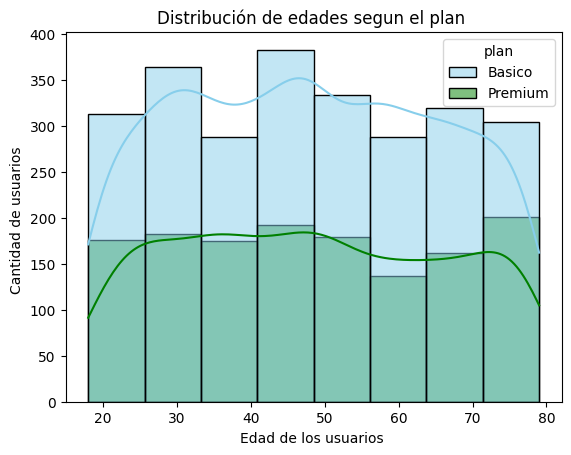

In [61]:
# Histograma para visualizar la edad (age)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=user_profile, x= 'age', hue='plan', palette=['skyblue', 'green'], bins=8, kde=True)
plt.xlabel('Edad de los usuarios ')
plt.ylabel('Cantidad de usuarios ')
plt.title('Distribución de edades segun el plan ')
plt.show()

💡Insights:
- Tipo de distribución: Presenta una distribución prácticamente simétrica y uniforme a lo largo del rango de 18 a 79 años (con una media de 48.1 años y mediana de 47.0 años). El pico pronunciado alrededor de los 47 años es efecto directo de la imputación con la mediana realizada sobre los valores centinela (-999).

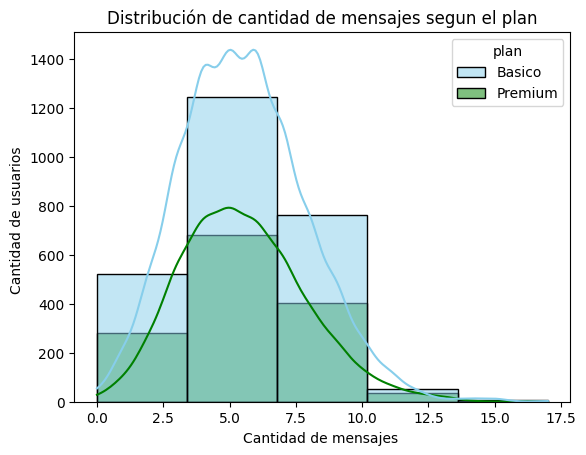

In [57]:
# Histograma para visualizar la cant_mensajes
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=user_profile, x= 'cant_mensajes', hue='plan', palette=['skyblue', 'green'], bins=5, kde=True)
plt.xlabel('Cantidad de mensajes ')
plt.ylabel('Cantidad de usuarios ')
plt.title('Distribución de cantidad de mensajes segun el plan')
plt.show()

💡Insights:
- Tipo de distribución: Presenta una distribución prácticamente simétrica y uniforme a lo largo del rango de 18 a 79 años (con una media de 48.1 años y mediana de 47.0 años). El pico pronunciado alrededor de los 47 años es efecto directo de la imputación con la mediana realizada sobre los valores centinela (-999).

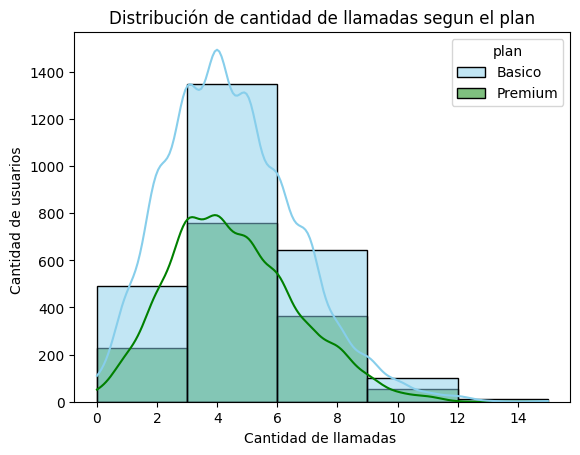

In [58]:
# Histograma para visualizar la cant_llamadas
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=user_profile, x= 'cant_llamadas', hue='plan', palette=['skyblue', 'green'], bins=5, kde=True)
plt.xlabel('Cantidad de llamadas ')
plt.ylabel('Cantidad de usuarios ')
plt.title('Distribución de cantidad de llamadas segun el plan')
plt.show()

💡Insights:
- Tipo de distribución: Presenta una distribución unimodal ligeramente sesgada a la derecha, concentrando al 50% central de los usuarios entre 3 y 6 llamadas (mediana de 4.0 y promedio de 4.47), con casos puntuales que alcanzan un máximo de 15 llamadas.
- Comportamiento por plan: No se aprecia diferencia en el hábito de llamadas entre planes; tanto los clientes del plan Básico como los de Premium tienden a realizar entre 3 y 6 llamadas con la misma distribución relativa


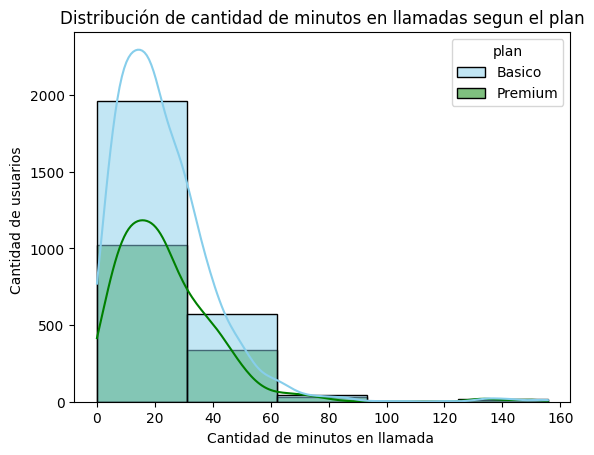

In [60]:
# Histograma para visualizar la cant_minutos_llamada
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=user_profile, x= 'cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], bins=5, kde=True)
plt.xlabel('Cantidad de minutos en llamada ')
plt.ylabel('Cantidad de usuarios ')
plt.title('Distribución de cantidad de minutos en llamadas segun el plan')
plt.show()

💡Insights:
- Tipo de distribución: Tiene una distribución con un marcado sesgo a la derecha (asimétrica positiva). El grueso de los usuarios acumula entre 11.1 y 31.4 minutos (mediana de 19.77 min), pero los valores extremos estiran el promedio hasta 23.29 min y alcanzan un máximo de 155.69 min.
- Comportamiento por plan: Ambos planes siguen exactamente la misma tendencia concentrada en consumos bajos. Incluso los usuarios con consumos atípicos (~155 min) apenas superan el límite del plan Básico (100 min incluidos) y quedan muy lejos del tope del plan Premium (600 min incluidos), lo que sugiere que muchos clientes Premium están subutilizando su plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

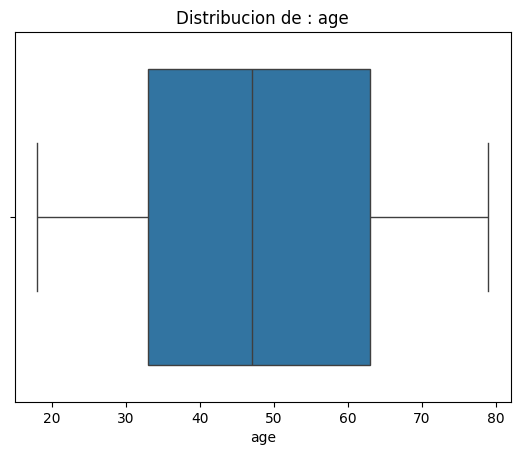

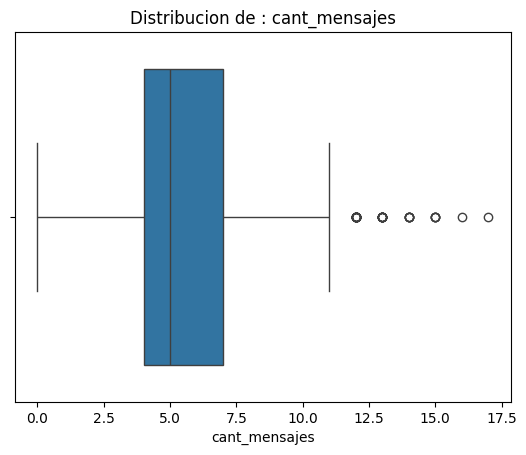

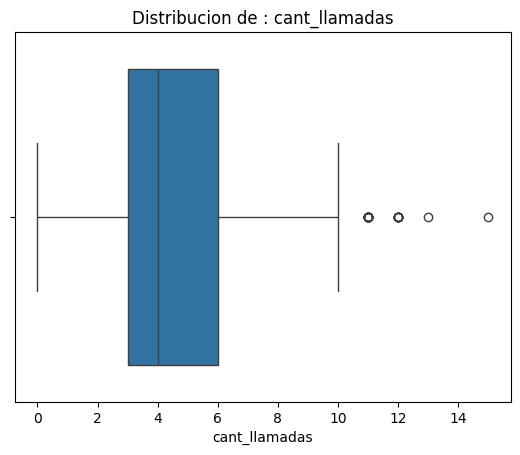

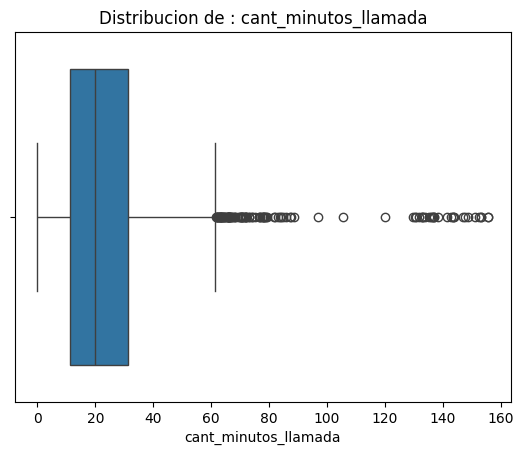

In [62]:
# Visualizando usando BoxPlot

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas :
    sns.boxplot(data=user_profile, x= col)
    plt.title(f'Distribucion de : {col}')
    plt.show()

💡Insights:
- Age: Presenta un rango intercuartílico (IQR) amplio (30 años, entre 33 y 63 años) que refleja una alta dispersión en el 50% central de los clientes. Su distribución es simétrica (mediana centrada en 47 años y bigotes equilibrados) y no presenta valores atípicos (outliers)
- cant_mensajes: Muestra un IQR compacto (3 mensajes, entre 4 y 7) donde se concentra la mayoría de los usuarios. Presenta una distribución asimétrica con sesgo a la derecha y valores atípicos (outliers) en el extremo superior (usuarios con más de 11.5 mensajes, llegando hasta 17).
- cant_llamadas: Presenta igualmente un IQR estrecho (3 llamadas, entre 3 y 6) con baja dispersión central, asimetría positiva (bigote superior más largo) y presencia de valores atípicos por encima del límite superior (más de 10.5 llamadas, alcanzando hasta 15).  
- cant_minutos_llamada: El 50% central se ubica entre 11.09 y 31.36 minutos (IQR = 20.27 min), pero la caja luce comprimida hacia la izquierda debido a un fuerte sesgo a la derecha y una alta concentración de outliers superiores que superan el límite de 61.76 minutos, extendiéndose hasta 155.69 minutos.

In [63]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites :
    #calcular Q1
    print('calculos de limites con el metodo IQR de la columna:',col)
    print()
    Q1= user_profile[col].quantile(0.25)
    print('Primer cuartil: ', Q1)
    #calcular Q3
    Q3 = user_profile[col].quantile(0.75)
    print('Tercer cuartil: ', Q3)
    #calcular IQR
    IQR = Q3 - Q1
    print('IQR: ', IQR)
    upper = Q3 + 1.5*IQR
    print('limite superior ',upper)
    lower = Q1 - 1.5*IQR
    print('limite inferior ',lower)
print('-' * 50)



calculos de limites con el metodo IQR de la columna: cant_mensajes

Primer cuartil:  4.0
Tercer cuartil:  7.0
IQR:  3.0
limite superior  11.5
limite inferior  -0.5
calculos de limites con el metodo IQR de la columna: cant_llamadas

Primer cuartil:  3.0
Tercer cuartil:  6.0
IQR:  3.0
limite superior  10.5
limite inferior  -1.5
calculos de limites con el metodo IQR de la columna: cant_minutos_llamada

Primer cuartil:  11.085
Tercer cuartil:  31.355
IQR:  20.27
limite superior  61.760000000000005
limite inferior  -19.32
--------------------------------------------------


In [64]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.518380,4.471618,23.288867
std,2.358046,2.142878,18.161719
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.085000
50%,5.000000,4.000000,19.770000
75%,7.000000,6.000000,31.355000
max,17.000000,15.000000,155.690000


💡Insights:

- **cant_mensajes:** mantener o no outliers, porqué? (Límite superior = 11.5 | Máximo = 17.0): Se mantienen los outliers. Enviar hasta 17 mensajes es un volumen totalmente factible en la realidad (no es un error de captura), y descartar a estos usuarios ocultaría el comportamiento del segmento más activo en mensajería.
- **cant_llamadas:** (Límite superior = 10.5 | Máximo = 15.0): Se mantienen los outliers. Realizar entre 11 y 15 llamadas representa a clientes con una frecuencia de comunicación hasta tres veces mayor al promedio, información clave para perfilar los niveles de uso.
- **cant_minutos_llamada:** (Límite superior = 61.76 min | Máximo = 155.69 min): Se mantienen los outliers. Aunque estadísticamente se alejan de la mediana (19.77 min), corresponden a clientes reales de alto consumo telefónico (potenciales clientes de alto valor o candidatos a planes superiores), por lo que conservarlos es indispensable para la etapa de segmentación.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [66]:
# Crear columna grupo_uso
# Función para clasificar uso
def classify_use(row):
    call= row['cant_llamadas']
    text= row['cant_mensajes']
# Manejo de valores nulos/faltantes
    if pd.isna(call) or pd.isna(text):
        return "Error en Datos"
# Segmentación
    if call < 5 and text < 5 :
        return 'Bajo uso'
    elif call < 10 and text < 10 :
        return 'Uso medio'
    else:
        return "Alto uso"

# aplicar función y crear columna
user_profile["grupo_uso"] = user_profile.apply(classify_use, axis=1)

In [67]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,alto uso
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [68]:
# Crear columna grupo_edad
# Función para clasificar edad
def classify_age(row):
    edad= row['age']
# Manejo de valores nulos/faltantes
    if pd.isna(edad):
        return "Error en Datos"
# Segmentación
    if edad < 30 :
        return 'Joven'
    elif edad < 60 :
        return 'Adulto'
    else:
        return "Adulto Mayor"

# aplicar función y crear columna
user_profile["grupo_edad"] = user_profile.apply(classify_age, axis=1)

In [69]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,alto uso,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,alto uso,Adulto Mayor
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

/tmp/ipykernel_2033/3362227021.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=user_profile, x= 'grupo_uso', palette=['skyblue'])
/tmp/ipykernel_2033/3362227021.py:2: UserWarning: 
The palette list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(data=user_profile, x= 'grupo_uso', palette=['skyblue'])


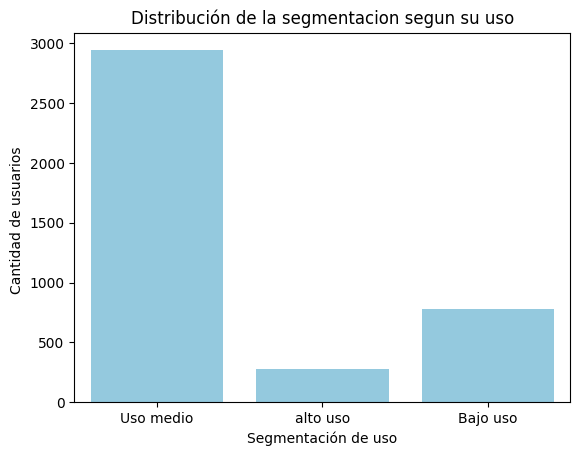

In [72]:

# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x= 'grupo_uso', palette=['skyblue'])
plt.xlabel('Segmentación de uso')
plt.ylabel('Cantidad de usuarios ')
plt.title('Distribución de la segmentacion segun su uso')
plt.show()


/tmp/ipykernel_2033/4288165247.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=user_profile, x= 'grupo_edad', palette=['skyblue'])
/tmp/ipykernel_2033/4288165247.py:2: UserWarning: 
The palette list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(data=user_profile, x= 'grupo_edad', palette=['skyblue'])


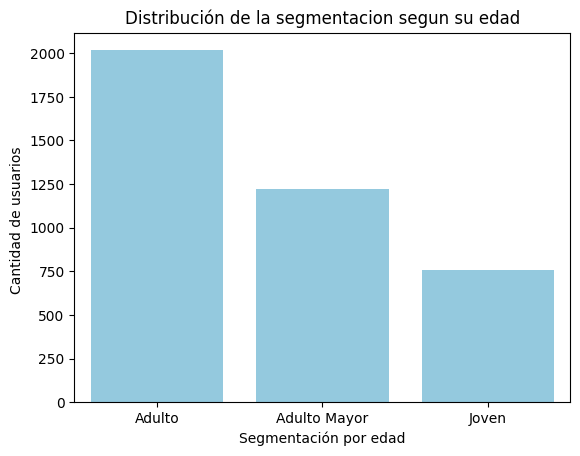

In [73]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x= 'grupo_edad', palette=['skyblue'])
plt.xlabel('Segmentación por edad')
plt.ylabel('Cantidad de usuarios ')
plt.title('Distribución de la segmentacion segun su edad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- **En users**, la columna churn_date presentó 3,534 nulos (88.35%), los cuales no eran errores sino el indicador de que el cliente sigue activo (solo 466 usuarios, el 11.65%, se dieron de baja).   En usage, las columnas duration (22,076 nulos / 55.19%) y length (17,896 nulos / 44.74%) se confirmaron como nulos estructurales tipo MAR (Missing At Random), ya que el 99.93% de su ausencia depende directamente del tipo de evento (call vs. text). Se mantuvieron intactos para no distorsionar las métricas.
- **Valores centinela** (sentinels) y datos faltantes reales:En city (users), además de los 469 nulos iniciales (11.725%), se detectaron 96 registros con el centinela '?' (2.4%), sumando en total 565 registros sin ciudad conocida (14.125%) que se estandarizaron como valores ausentes (<NA>) para dejar únicamente las 6 ciudades reales.
- **En age** (users), se encontraron edades negativas imposibles (-999) que sesgaban el promedio inicial a 33.74 años (con desviación estándar de 123.23); al imputarlos con la mediana (47.0 años), el promedio real se estabilizó en 48.12 años.
- **Fechas imposibles y ausentes**:En reg_date (users), se detectaron 40 registros (1.0%) con una fecha futura repetida (2026-05-10, fuera del corte de 2024), los cuales fueron convertidos a NaT.   En date (usage), se identificaron 50 registros nulos (NaT, equivalentes al 0.125%), los cuales se descartaron al filtrar los eventos válidos de 2024 sin introducir sesgo estadístico.   

🔍 **Segmentos por Edad**
- La cartera de 3,999 clientes activos con uso en 2024 muestra una distribución simétrica entre los 18 y 79 años (mediana de 47 años y rango intercuartílico de 33 a 63 años):   Adulto (30 a 59 años): Representa el núcleo principal y más numeroso de ConnectaTel, impulsado además por la concentración alrededor de la mediana (47 años).
- Adulto Mayor (60 años o más): Conforma el segundo grupo más relevante (más del 25% de la cartera supera los 63 años), mostrando una alta fidelidad al servicio tradicional de voz y SMS.   Joven (menores de 30 años): Es el segmento minoritario (menos del 25% de la base tiene menos de 33 años).
- Al cruzar la edad con los planes (64.87% en Básico con 2,594 usuarios y 35.13% en Premium con 1,405 usuarios), se observa que la edad no condiciona el tipo de plan contratado ni el volumen de consumo, manteniendo proporciones idénticas en todos los rangos etarios.   

📊 **Segmentos por Nivel de Uso**
- **Uso medio (entre 5 y 9 llamadas o mensajes):** Es el segmento predominante de la empresa. El cliente típico de ConnectaTel realiza una mediana de 4 llamadas (promedio de 4.47), envía 5 mensajes (promedio de 5.52) y consume 19.77 minutos (promedio de 23.29 min).
- **Bajo uso (< 5 llamadas y < 5 mensajes):**
-  Representa el segundo bloque de usuarios; clientes con actividad mínima que subutilizan incluso la cuota del plan Básico (que incluye 100 minutos y 100 SMS por $12 USD).
-  **Alto uso (10 o más llamadas o mensajes) y Outliers:** Es un segmento reducido donde se ubican los valores extremos detectados mediante el método IQR: usuarios que superan los 11.5 mensajes (máximo de 17), las 10.5 llamadas (máximo de 15) y los 61.76 minutos (máximo de 155.69 minutos).

- **¿Qué segmentos son más valiosos y qué implican los outliers?**


**Por rentabilidad actual:**
Los clientes del Plan Premium (25 USD/mes) con Uso medio o Bajo son actualmente los más rentables en margen directo, ya que pagan más del doble que el plan Básico ($12 USD) pero consumen exactamente lo mismo (menos de 32 minutos y 7 mensajes en el 75% de los casos), dejando intactos los 600 minutos y 500 mensajes de su paquete. Sin embargo, tienen un alto riesgo de churn (baja) o downgrade si perciben que están pagando por capacidad que no utilizan.


**Por potencial de upselling (Outliers):** Los usuarios con outliers en duración de llamadas (62 a 155.69 minutos) que pertenecen al Plan Básico son los únicos que rebasan el límite de 100 minutos incluidos en su tarifa, generando cobros por excedente (0.10 USD/minuto) y convirtiéndose en el segmento clave para migrar a planes superiores.   
**➡️ Esto sugiere que ...**

Existe una desconexión importante entre el diseño actual de los planes (Básico y Premium) y el comportamiento real de uso de voz y SMS. Ambos planes tienen un comportamiento de consumo idéntico en llamadas y mensajes, y más del 95% de los usuarios consume menos de 62 minutos y menos de 12 mensajes, quedando muy por debajo de los topes incluidos (100 min / 100 SMS en Básico y 600 min / 500 SMS en Premium). Esto indica que la diferenciación real por la que un usuario elige el plan Premium probablemente radica en los datos móviles (20 GB vs. 5 GB) y no en los minutos o mensajes de texto.

  💡 **Recomendaciones**
1. **Campaña de Upselling dirigida a los Outliers del Plan Básico:** Identificar a los usuarios del segmento Alto uso en el plan Básico que superan los 100 minutos de llamada (llegando hasta 155.69 min). Al pagar excedentes de 0.10 USD por minuto extra, su factura mensual se acerca al costo del plan Premium (25 USD), por lo que ofrecerles una migración promocional al plan Premium o a un plan intermedio asegurará ingresos recurrentes fijos y mayor satisfacción.   
2. **Estrategia de Retención y Valor Agregado para clientes Premium de Bajo/Medio Uso:** Dado que el 35.13% de la cartera paga el plan Premium pero consume lo mismo en voz y SMS que el plan Básico, se recomienda reforzar los beneficios percibidos de su plan (mayor velocidad o bonos de GB, roaming o servicios digitales incluidos) para justificar los 25 USD mensuales y prevenir la fuga de clientes (churn, que hoy acumula un 11.65% histórico).   
3. **Creación de un "Plan Lite / Conecta Joven" ($8 - $9 USD) y reestructura de cuotas:** Diseñar una tarifa de entrada enfocada en el segmento de Bajo uso y en captar mayor cuota del mercado Joven (< 30 años, actualmente el menor segmento), reduciendo los minutos y SMS incluidos (ej. 50 min y 50 SMS, que cubren de sobra la media real de 23 min y 5.5 SMS) pero manteniendo una bolsa atractiva de datos móviles (8 a 10 GB).

Link a repositorio público del proyecto: `LINK a tu repo aquí`